<a href="https://colab.research.google.com/github/savnjordan/MPM_200_Jordan/blob/main/notebooks/Updated_R_Hummingbird_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [ ]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Savannah!", by = "shark")


 __________________________________________ 
< Welcome to Hummingbird HQ, Dr. Savannah! >
 ------------------------------------------ 
           \
            \

              /""-._
              .       '-,
               :          '',
                ;      *     '.
                 ' *         () '.
                   \               \
                    \      _.---.._ '.
                    :  .' _.--''-''  \ ,'
        .._           '/.'             . ;
        ; `-.          ,                \'
         ;   `,         ;              ._\
          ;    \     _,-'                ''--._
          :    \_,-'                          '-._
          \ ,-'                       .          '-._
          .'         __.-'';            \...,__       '.
        .'      _,-'        \              \   ''--.,__  '\
        /    _,--' ;         \              ;           \^.}
        ;_,-' )     \  )\      )            ;
             /       \/  \_.,-'             ;
            /         

In [ ]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [ ]:
data <- read.csv("Hummingbird_data.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [ ]:
dim(data)

[1] 6908   12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [ ]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** The columns dispotition, place, F_aid, species, sex, age, season, reason, Green_Orange, and ID are text, while the columns admitted and brought in after are numbers. Yes, admitted is stored as a date.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [ ]:
set.seed(425)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [ ]:
str(model_data)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "8/31/2001" "2/20/2001" "5/6/2015" "3/13/2001" ...
 $ Disposition_binary: chr  "Died" "Died" "Died" "Released" ...
 $ Place             : chr  "Lindsey" "Lindsey" "malibu" "Lindsey" ...
 $ F_Aid             : chr  "No" "No" "Yes" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "Selasphorus" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 0 2 0 0 0 0 0 0 0 ...
 $ season            : chr  "Summer" "Winter" "Spring" "Spring" ...
 $ r                 : chr  "window hit" "found on the ground" "found on the ground" "caught by domestic animal" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "2119_ANHU" "1961_ANHU" "6409_ALHU" "1985_ANHU" ...


**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:** The columns Disposition, place, F_Aid, species, sex, age, season, reason, and Green_orange are categorical. None of the columns are continous. ID can be a useful variable when looking at characterisitics of an individual, however it may not be useful for analysis since it is used for individual identification.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [ ]:
write.csv(model_data, "outputs/Hummingbird_data_Savannah_Jordan.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [ ]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4127
Santa Barbara,72
malibu,801


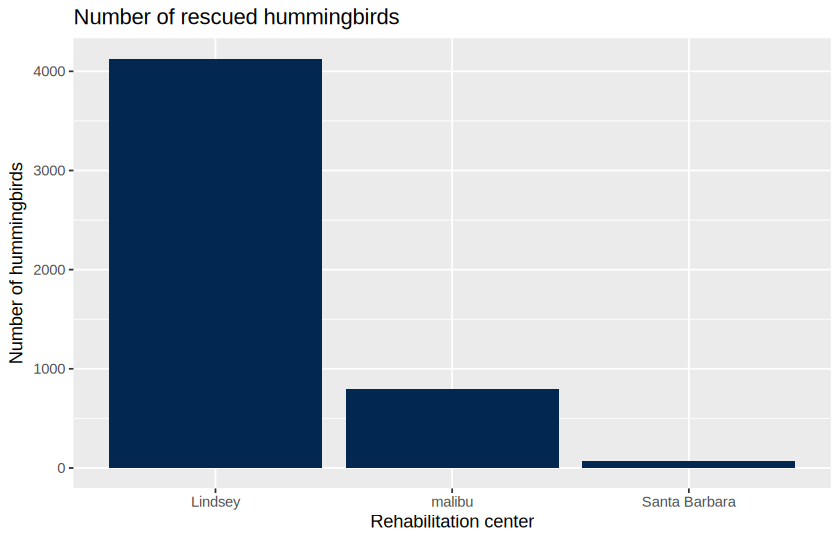

In [ ]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [ ]:
ggsave("outputs/rehab_counts_Savannah_Jordan.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:** In the code to create "rehab", the function "group_by" used the values from the column "Place" and created a group for each of the possible values for place, resulting in 3 categories including Lindsey, Santa Barbara, and Malibu. Then the function "summarise" was used to determine the counts of individuals within each of the 3 locations.

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?



✍️ **Your answer:** No, even though that are more birds at Lindsey, it does not mean that more birds die at Lindsey. These raw counts are not enough to compare outcomes between centers because they all differ in the total number of hummingbirds patients and there are various factors that impact their outcomes, therefore to compare outcomes, the total number of patients and within each center and the other variables needs to be considered.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [ ]:
df_F_Aid <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_F_Aid

df_r <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_r

df_Age_e <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df_Age_e

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2084
No,Released,1214
Yes,Died,1094
Yes,Released,608


r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,457
caught by domestic animal,Released,181
found inside,Died,117
found inside,Released,45
found on the ground,Died,1425
found on the ground,Released,737
nest-related,Died,279
nest-related,Released,425
suspect torpor-like state,Died,89


Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,440
Nestling,Released,782
adult-like,Died,2738
adult-like,Released,1040


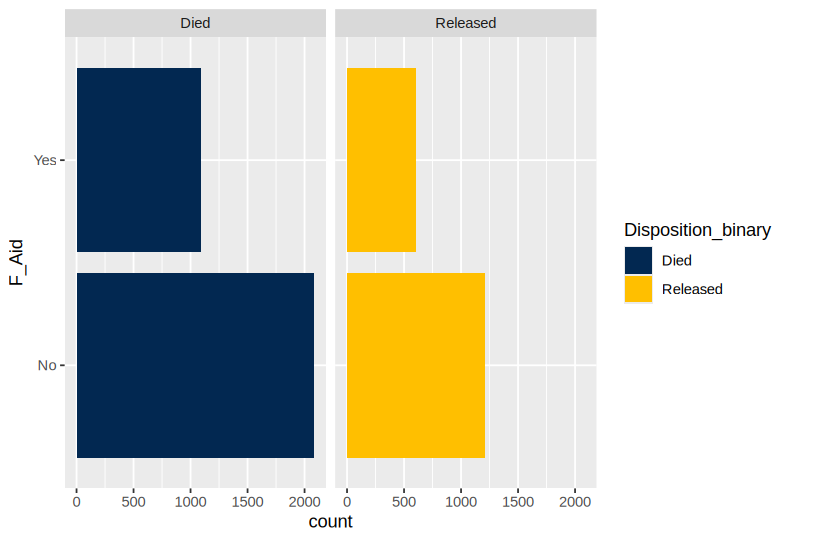

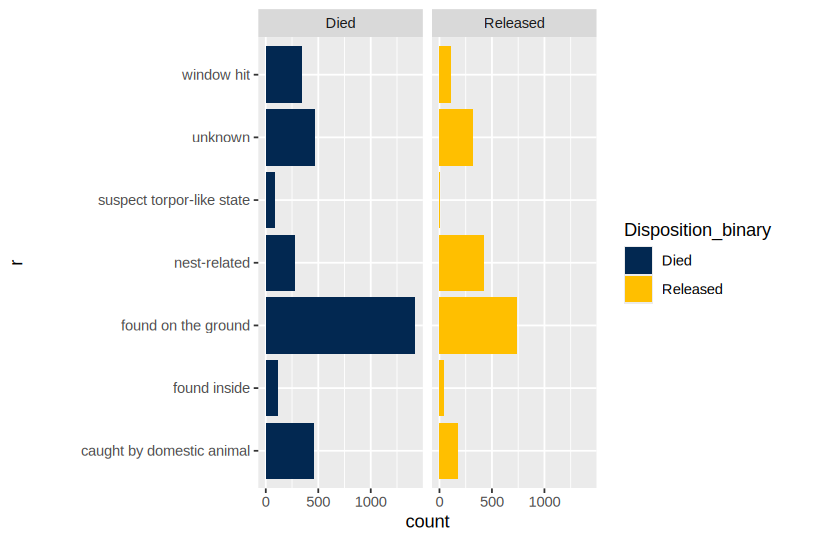

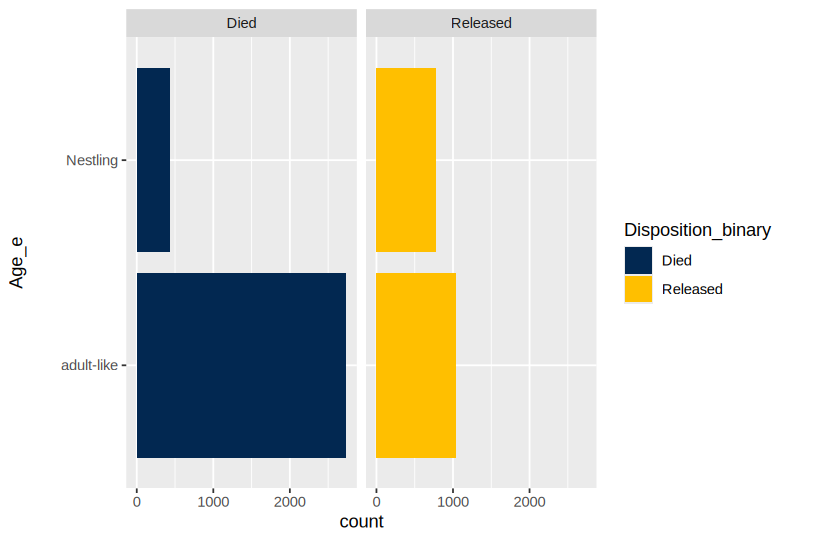

In [ ]:
ggplot(df_F_Aid, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df_r, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df_Age_e, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:** For the first variable "first aid", greater amounts of individuals that died did not receive first aid, however greater amounts of individuals that were released also did not receive first aid. For the second variable "reason", the greatest amount of individuals that died and individuals that were released were found on the ground. Lastly for age, out of the individuals that died, a greater amount were adult-like, while out of the individuals that were released, there was a smaller difference between nestlings and adult-like. Age and reason for admission look associated with the outcome. A Chi-square test of independence could be used to determine if there is an association.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2644,0.6406591
Lindsey,Released,1483,0.3593409
Santa Barbara,Died,43,0.5972222
Santa Barbara,Released,29,0.4027778
malibu,Died,491,0.6129838
malibu,Released,310,0.3870162


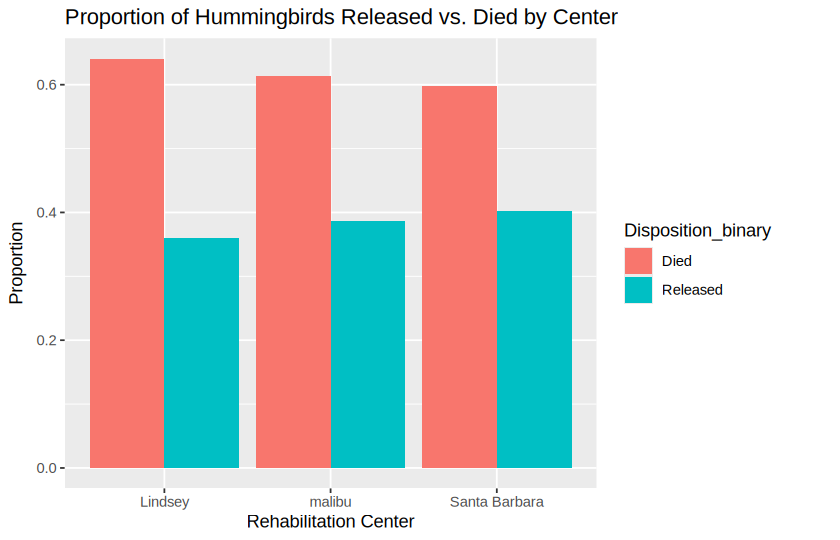

In [ ]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Center") +
  ylab("Proportion") +
  labs(title = "Proportion of Hummingbirds Released vs. Died by Center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4125                0
  Selasphorus                        0              875

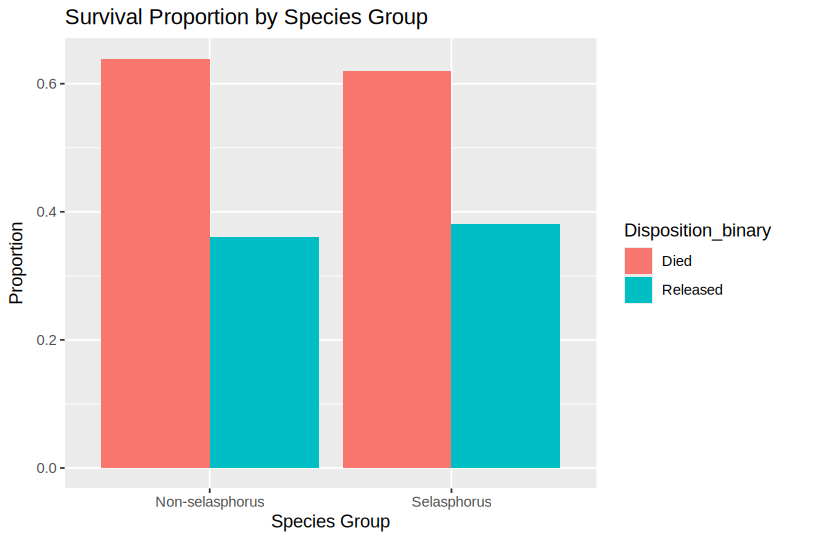

In [ ]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")%>%
  group_by(Species_group)%>%
  mutate(proportion = count / sum(count))

ggplot(species_distribution, aes(x = Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species Group") +
  ylab("Proportion") +
  labs(title = "Survival Proportion by Species Group")

✍️ **Your answer:** The survival proportions do not differ between species groups, the graph shows that the proportions are similar by species group.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [ ]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-05" "2016-12-19"

✍️ **Your answer:** The format argument is used to show how the date is read, in which the month is read first, then day and year. Using %d/%m/%Y would result in the day being read first, then month and year, which would change the format of the date.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `____` Why?

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [ ]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(admissions = n())

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(admissions = n())

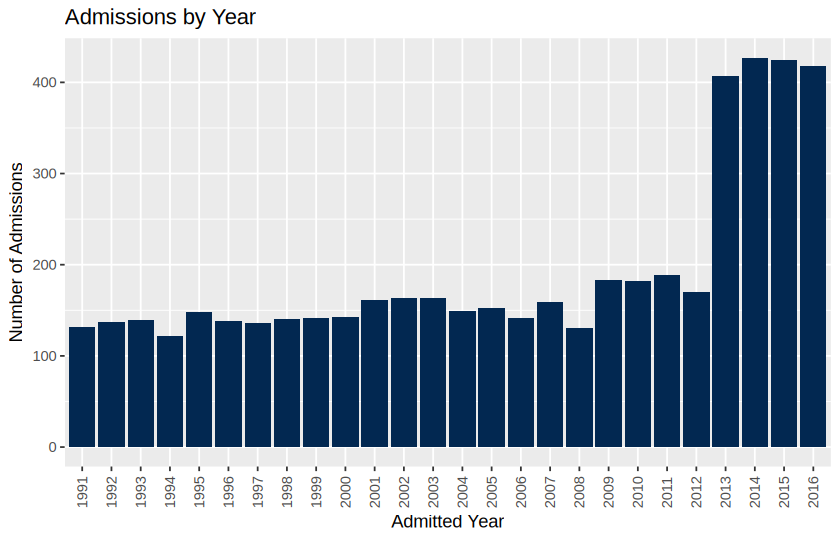

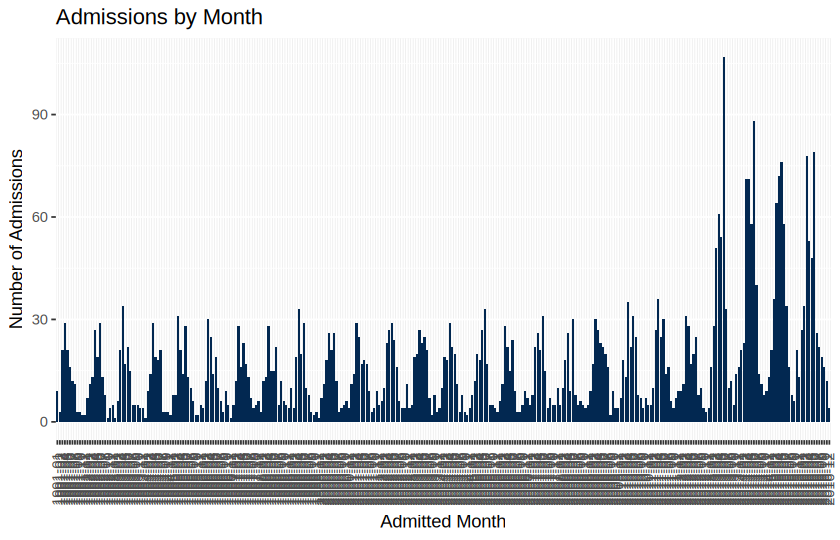

In [ ]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = admissions)) +
  geom_col(fill = "#022851") +
  xlab("Admitted Year") +
  ylab("Number of Admissions") +
  labs(title = "Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = admissions)) +
  geom_col(fill = "#022851") +
  xlab("Admitted Month") +
  ylab("Number of Admissions") +
  labs(title = "Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_month and Species_group.
ℹ Output is grouped by Admitted_month.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_month, Species_group))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


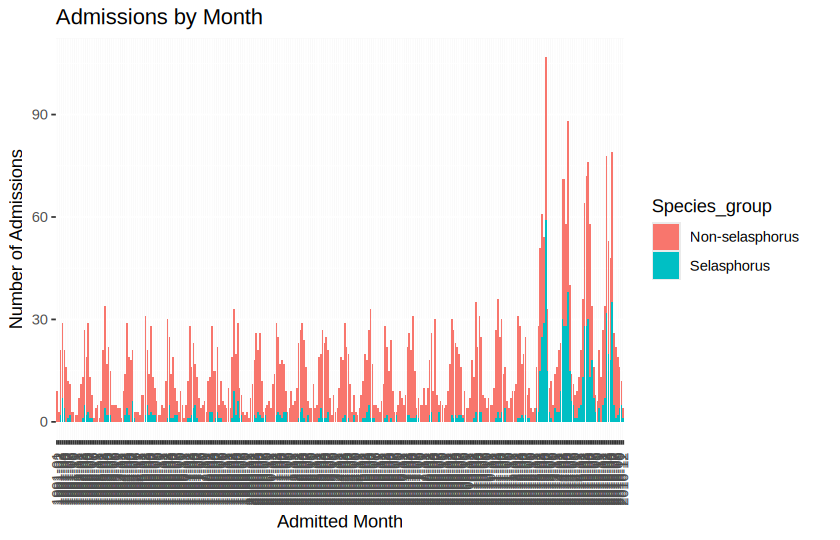

In [ ]:
#Admissions for two different species groups over time
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(admissions = n())

ggplot(admissions_by_month, aes(x = Admitted_month, y = admissions, fill = Species_group)) +
  geom_col() +
  xlab("Admitted Month") +
  ylab("Number of Admissions") +
  labs(title = "Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [ ]:
# your investigation here
admissions_by_year_place <- model_data %>%
  count(Admitted_year = format(Admitted_date, "%Y"), Place)
admissions_by_year_place

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,132
1992,Lindsey,137
1993,Lindsey,139
1994,Lindsey,122
1995,Lindsey,148
1996,Lindsey,138
1997,Lindsey,136
1998,Lindsey,140
1999,Lindsey,142


✍️ **Your answer:** The Lindsey center first appeared in 1991, the Malibu center first appeared in 2012, and the Santa Barbara center first appeared in 2016. The increase in admissions from 2013 onwards is caused by the opening of more centers, which increases the amount of patients admitted.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [ ]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:** One thing in this data that suprise me was seeing how the different factors, including place, reason of admission, season, etc. affected the outcome of survival. One R error that I hit included a graph not being produced correctly. I fixed it by going back through the code and making sure the correct names, values, and formats were used in order to correctly demonstrate the data that the question was asking and correctly resulting in a graph.  

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄

# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [ ]:
fullmodel  = glm(__________ ~ r + Green_Orange + season+F_Aid+Species_e, data = _______, family= binomial(link = logit))
fullmodel

2. use following command with full model to do stepwise model selection

In [ ]:
backward_model = step(__________,k=2,direction = "backward",test="Chisq")

In [ ]:
forward_model = step(___________,k=2,direction = ,test="Chisq")

### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [ ]:
names(backward_model)

explore individual attributes of the fitted model and read about it in the R documentation

In [ ]:
library(sjPlot)

In [ ]:
tab_model(backward_model)